# 06-机械臂运动学正解


## 1. 本篇范围与核心问题

上一篇用 URDF 描述了连杆、关节和它们的连接关系。有了机械臂结构，接下来要回答：**已知各关节的位置，怎样算出末端在空间中的位置和朝向？**

这就是运动学正解，也称正运动学（Forward Kinematics，FK）。课件标题为“机器人运动学正解：从直观几何到严谨代数”。

本篇依据 `具身智能实现03-运动学正解.pptx` 的全部 **32 页**整理。课程先通过单连杆与二连杆模型推导几何公式，再引入旋转、平移和齐次变换矩阵，最后使用 Python、IKPY 与 NumPy 计算和验证。

课件中的推导主要针对**二自由度平面旋转机械臂**。三维运动学在这里用于解释矩阵方法的必要性，没有展开完整三维机械臂的建模实例。


## 2. 关节空间与任务空间

课件第 2 页先区分两种描述机器人状态的坐标体系。

| 空间 | 描述对象 | 课件示例 |
|---|---|---|
| 关节空间（Joint Space） | 机器人各关节的变量与自身构型 | `q = [θ₁, θ₂, ..., θₙ]` |
| 任务空间（Task Space） | 末端在工作环境中的位置与朝向 | `X = [x, y, z, α, β, γ]` |

关节空间回答“各关节转到什么角度”，任务空间回答“末端在哪里、朝向哪里”。

**位姿**同时包含位置和姿态。三维位置通常用 `x、y、z` 表示，朝向还需要其他参数或旋转矩阵表示。

> **补充说明：**课件的 `θ` 对应本节旋转关节的角度；如果机器人包含移动关节，关节变量也可以是位移。`α、β、γ` 在此只表示姿态参数，使用时还需要明确旋转顺序和坐标系约定，不能只凭三个数就确定唯一的解释。

### 2.1 正解的数学形式

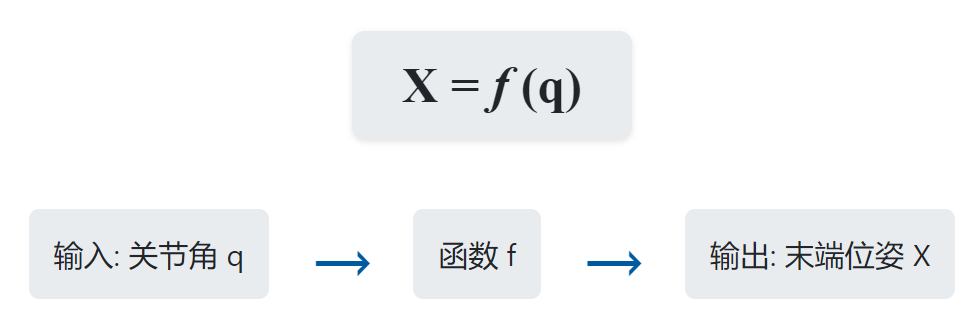

正解是在机器人结构与参考坐标系确定后，求一个映射：

$$
\mathbf X=f(\mathbf q)
$$

输入是已知的关节变量，输出是模型计算出的末端位姿。

> **补充说明：**课件使用“确切位姿”表述数学模型中的计算结果。实体机械臂的实际位置还会受到尺寸误差、齿隙和形变等因素影响，不能只凭理想正解公式判断实机精度。


## 3. 几何法与矩阵法

课件第 4 页比较两种主要方法。

| 方法 | 基本思路 | 课程强调的特点 |
|---|---|---|
| 齐次变换矩阵法 | 用线性代数描述坐标系之间的旋转、平移，再做矩阵连乘 | 形式统一，易于编程，适合复杂结构 |
| 解析几何与三角函数法 | 根据几何关系，用三角函数计算位置 | 图像直观，但复杂结构的推导较繁琐 |

课件先采用几何法，让读者理解每段连杆怎样贡献末端位置，再把相同的过程写成矩阵运算。

两种方法应在相同模型、角度定义和坐标系约定下得到一致结果。后面的代码示例也围绕这一点进行验证。


## 4. 单连杆模型与投影公式

课件第 7 页建立最简单的平面模型：

- 一个旋转关节固定在参考坐标系 `{0}` 的原点 `O`。
- 连杆长度为 `L₁`。
- 关节角 `θ₁` 是连杆相对于参考 X 轴的夹角。
- 目标是求末端点 `P₁` 的坐标 `(X₁, Y₁)`。

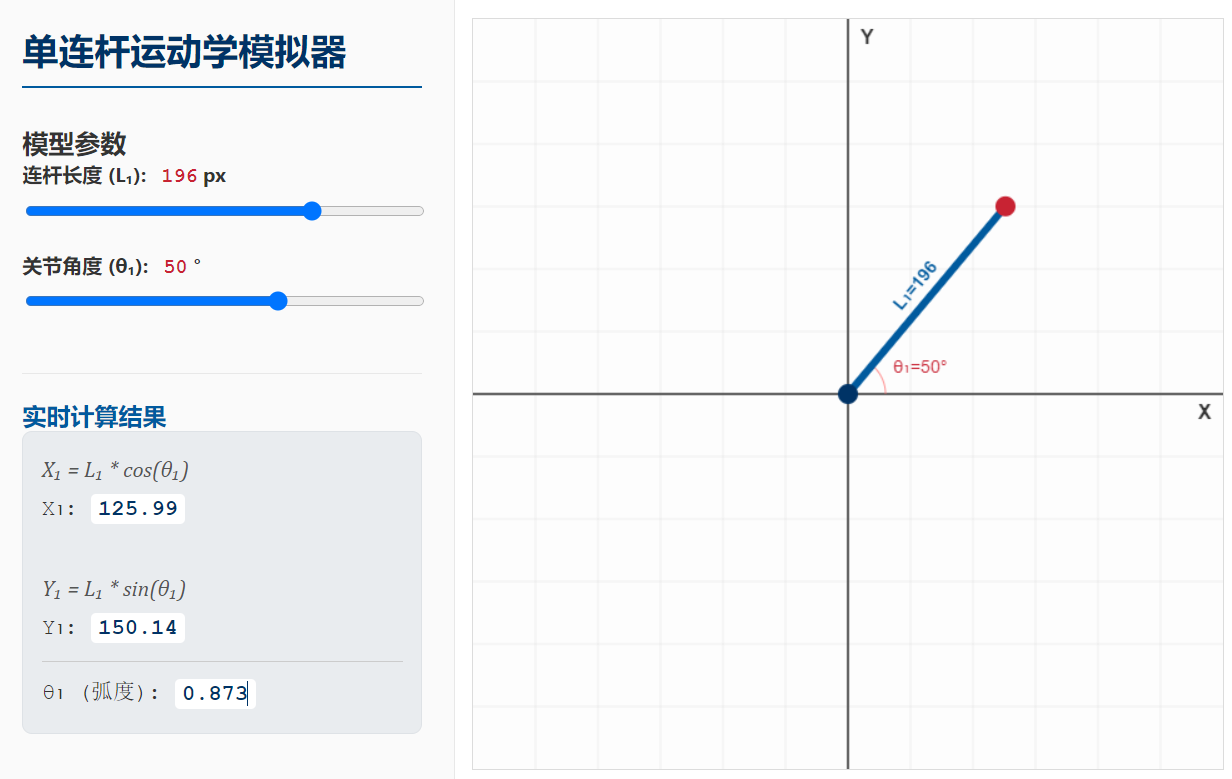

连杆在 X、Y 两个方向上的投影分别给出：

$$
X_1=L_1\cos\theta_1,\qquad Y_1=L_1\sin\theta_1
$$

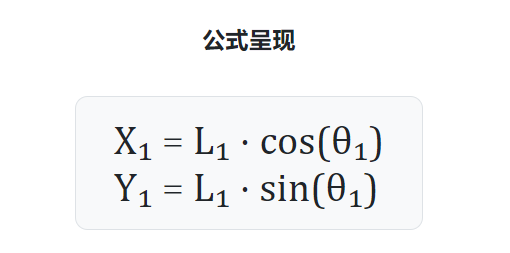

这就是最基本的一级运动学正解：已知固定的连杆长度和一个关节角，计算末端平面坐标。

图中示例使用 `L₁ = 196 px`、`θ₁ = 50°`，所以显示的 `X₁ ≈ 125.99`、`Y₁ ≈ 150.14` 也是像素单位。实际模型使用米时，坐标结果才对应米。

> **补充说明：**公式按常用平面约定取逆时针为正。连杆长度与输出坐标必须使用一致的长度单位。编程调用三角函数时还要确认角度是否已经转成弧度。


## 5. 二连杆模型与第二关节的角度定义

课件第 9 页在第一段连杆末端增加第二段连杆：长度为 `L₂`，由第二个旋转关节驱动，关节变量为 `θ₂`。

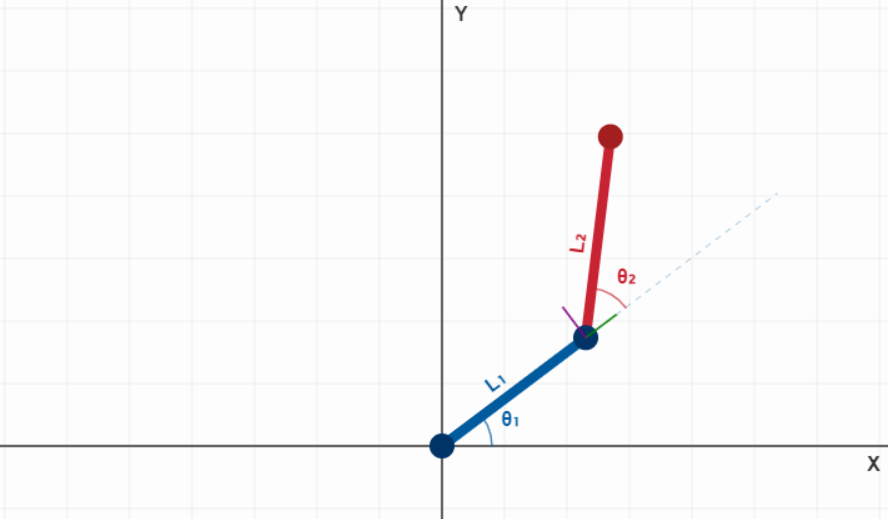

本例的关键条件是：**`θ₂` 相对于第一连杆的延长线定义。**它表示第二连杆相对于第一连杆的转角，而不是第二连杆直接相对于全局 X 轴的角度。

因此，第二连杆在全局平面中的朝向是：

$$
\theta_1+\theta_2
$$

当 `θ₂ = 0` 时，两段连杆沿同一方向伸直。如果把 `θ₂` 误当成全局角度，后面的坐标公式就会使用错误的投影方向。


## 6. 局部坐标系与矢量叠加

### 6.1 在 `P₁` 建立局部坐标系

课件第 10 页在第一连杆末端 `P₁` 建立坐标系 `{1}`。它的 X′ 轴沿第一连杆的方向，随着第一连杆一起运动。

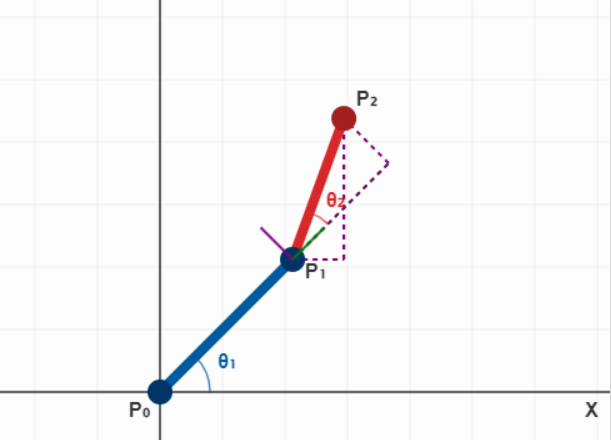

在这个局部坐标系中，第二段连杆又变成了一个单连杆问题：

$$
X'_2=L_2\cos\theta_2,\qquad Y'_2=L_2\sin\theta_2
$$

`X′₂、Y′₂` 描述从 `P₁` 到 `P₂` 的局部位移。它们使用的轴方向随第一连杆变化，不能直接加到全局的 `X₁、Y₁` 上。

### 6.2 转成全局分量再相加

将局部位移转到全局坐标系后，第二段连杆贡献的位移为：

$$
\Delta X=L_2\cos(\theta_1+\theta_2),\qquad
\Delta Y=L_2\sin(\theta_1+\theta_2)
$$

然后按课件的矢量叠加思想，将两段贡献相加：

$$
\overrightarrow{OP_2}=\overrightarrow{OP_1}+\overrightarrow{P_1P_2}
$$

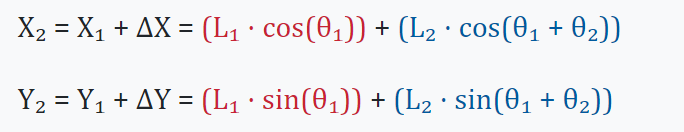

最终得到：

$$
\begin{aligned}
X_2&=L_1\cos\theta_1+L_2\cos(\theta_1+\theta_2)\\
Y_2&=L_1\sin\theta_1+L_2\sin(\theta_1+\theta_2)
\end{aligned}
$$

课件将这种思路概括为“局部求解，全局累加”：先在当前局部坐标系中解决简单问题，再变换到共同的坐标系中叠加。

> **补充说明：**上面两式计算末端位置。如果末端坐标系的 X 轴沿第二连杆，那么其平面朝向还可以写为 `φ = θ₁ + θ₂`。课件接下来的几何代码只返回 `X、Y`，矩阵代码则同时保留朝向信息。


## 7. 用 Python 实现解析公式

课件第 15 页将二连杆公式写成 NumPy 代码。

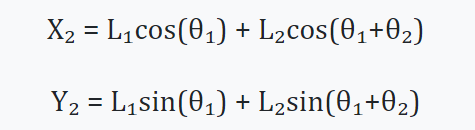

下面保留课程的函数、参数和示例输入，整理缩进，并将 PPT 中挤在一起的调用与打印语句拆成两行：

```python
import numpy as np

def forward_kinematics_2d(theta1, theta2, L1, L2):
    """计算二连杆末端坐标."""
    theta1_rad = np.deg2rad(theta1)
    theta2_rad = np.deg2rad(theta2)

    X = L1 * np.cos(theta1_rad) + L2 * np.cos(theta1_rad + theta2_rad)
    Y = L1 * np.sin(theta1_rad) + L2 * np.sin(theta1_rad + theta2_rad)
    return X, Y

# Example usage
pos_x, pos_y = forward_kinematics_2d(30, 45, 1.0, 0.8)
print(f"End-effector position: ({pos_x:.4f}, {pos_y:.4f})")
```

这个函数接收的 `theta1、theta2` 是**角度制**。`np.deg2rad` 将它们转为弧度，随后才传给 `np.cos`、`np.sin`。

`L1、L2` 使用什么长度单位，返回的 `X、Y` 就使用什么单位。如果输入已经是弧度，不能继续按本函数接口当作度转换。

### 7.1 核对课件示例

当 `θ₁ = 30°`、`θ₂ = 45°` 时，第二段连杆的全局朝向为 `75°`。代入得到：

$$
\begin{aligned}
X_2&=\cos30^\circ+0.8\cos75^\circ\approx1.07308064\\
Y_2&=\sin30^\circ+0.8\sin75^\circ\approx1.27274066
\end{aligned}
$$

对应的四位小数结果是 `End-effector position: (1.0731, 1.2727)`。

> **课件数值修正：**PPT 的输出注释写为 `(1.0733, 1.2821)`，与给定公式及输入不一致。本篇保留原输入，使用重新计算的 `(1.0731, 1.2727)`。后面的 NumPy 矩阵法和 IKPY 正解也得到相同坐标。


## 8. 几何法的局限与矩阵法的作用

课件第 16—19 页讨论问题变复杂后的处理方法。

在当前二维模型中，两段连杆都在同一平面内绕同向轴转动，可以通过角度相加得到第二段的全局朝向。

进入三维空间后，关节可能绕不同方向的轴旋转。单靠作图和三角函数逐项追踪坐标，推导容易变长，也更容易混淆姿态和坐标系。

齐次变换矩阵将旋转和平移放到同一个框架中，把多级坐标变换写成矩阵连乘。课件强调它的统一形式、通用性与数值计算便利性。

| 模型 | 齐次坐标 | 变换矩阵大小 |
|---|---|---|
| 二维 | `(x, y, 1)` | `3×3` |
| 三维 | `(x, y, z, 1)` | `4×4` |

> **补充说明：**课件说二维“总角度相加”的技巧进入三维后失效，主要指绕不同轴的旋转一般不能用角度简单相加。绕同一轴的旋转仍可合并。矩阵方法也需要正确的结构参数、坐标系和变换顺序，不能替代建模本身。


## 9. 旋转与平移的基本运算

### 9.1 二维旋转矩阵

课件第 21 页使用逆时针旋转角 `θ` 的矩阵：

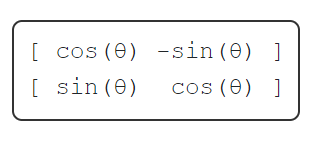

$$
R(\theta)=
\begin{bmatrix}
\cos\theta&-\sin\theta\\
\sin\theta&\cos\theta
\end{bmatrix}
$$

采用列向量表示点时，旋转可以写成：

$$
\begin{bmatrix}x_{\mathrm{new}}\\y_{\mathrm{new}}\end{bmatrix}
=R(\theta)\begin{bmatrix}x_{\mathrm{old}}\\y_{\mathrm{old}}\end{bmatrix}
$$

> **课件表述的边界：**PPT 写“旋转只改变方向／姿态，不改变位置”。纯旋转确实不引入坐标系原点的平移，但绕原点旋转一个非原点的点，会改变它的坐标。保持不变的是点到旋转原点的距离。

### 9.2 平移使用矢量加法

课件第 22 页给出：

$$
\begin{bmatrix}x_{\mathrm{new}}\\y_{\mathrm{new}}\end{bmatrix}
=\begin{bmatrix}x_{\mathrm{old}}\\y_{\mathrm{old}}\end{bmatrix}
+\begin{bmatrix}t_x\\t_y\end{bmatrix}
$$

平移改变位置，保持坐标系的方向不变。

旋转使用矩阵乘法，平移使用加法。如果希望统一表达并连续组合两者，就需要引入齐次坐标。


## 10. 齐次坐标与齐次变换

二维点 `(x, y)` 增加一个分量后写为列向量 `(x, y, 1)`。多出的 `1` 让平移也能通过矩阵乘法表达。

### 10.1 齐次旋转矩阵

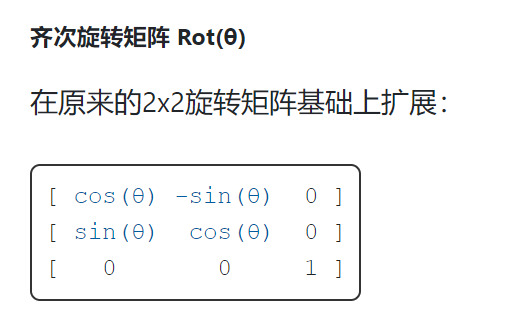

$$
\operatorname{Rot}(\theta)=
\begin{bmatrix}
\cos\theta&-\sin\theta&0\\
\sin\theta&\cos\theta&0\\
0&0&1
\end{bmatrix}
$$

### 10.2 齐次平移矩阵

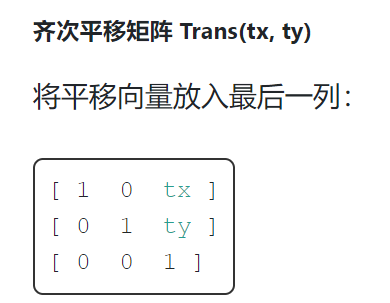

$$
\operatorname{Trans}(t_x,t_y)=
\begin{bmatrix}
1&0&t_x\\
0&1&t_y\\
0&0&1
\end{bmatrix}
$$

将它乘以 `(x, y, 1)`，结果为 `(x+tₓ, y+tᵧ, 1)`。原来的矢量加法因此转为统一的矩阵乘法。

### 10.3 合并旋转与平移

> **补充展开：**按照课件的两个基础矩阵，使用列向量、先旋转再按父坐标轴平移时，复合矩阵为：

$$
T=\operatorname{Trans}(t_x,t_y)\operatorname{Rot}(\theta)=
\begin{bmatrix}
\cos\theta&-\sin\theta&t_x\\
\sin\theta&\cos\theta&t_y\\
0&0&1
\end{bmatrix}
$$

左上角保存朝向，最后一列保存平移。同一块矩阵便能够把局部点变换到父坐标系中。


## 11. 矩阵乘法与变换顺序

课件第 25 页用一个点的连续变换说明顺序：先执行 `M₁`，再执行 `M₂`。

$$
P'=M_2(M_1P)=(M_2M_1)P
$$

使用列向量时，**最靠近点的右侧矩阵先作用**。两个矩阵可以先相乘得到复合变换，再统一作用于点。

矩阵乘法一般不满足交换律：`M₂M₁` 与 `M₁M₂` 通常不同。先旋转再平移，与先平移再旋转，可能得到不同的位置。

### 11.1 运动学链中的乘法方向

本篇沿用 PPT 的记号 `T₀¹、T₁²`，并明确它们的使用含义：

- `T₀¹`：将坐标系 `{1}` 中的坐标转换到 `{0}`。
- `T₁²`：将坐标系 `{2}` 中的坐标转换到 `{1}`。
- `T₀²`：将坐标系 `{2}` 中的坐标转换到 `{0}`。

所以：

$$
T_0^2=T_0^1T_1^2
$$

这里先用右侧 `T₁²` 将局部坐标转到 `{1}`，再用左侧 `T₀¹` 转到 `{0}`。它与“右侧先作用”的规则一致。


## 12. 二连杆齐次矩阵的展开

课件第 26 页将二连杆计算写成两个 `3×3` 矩阵的乘法。

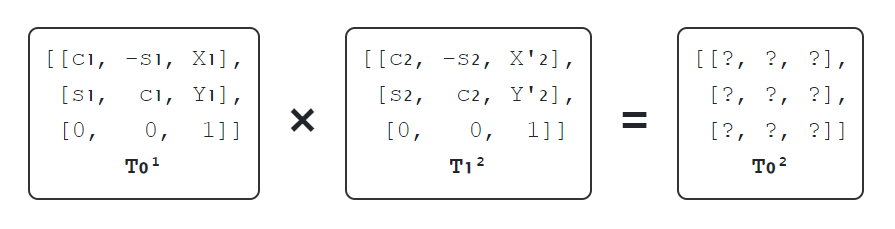

记 `c₁ = cos θ₁`、`s₁ = sin θ₁`，`c₂、s₂` 同理。第一连杆末端的坐标为 `X₁、Y₁`，第二段局部位移为 `X′₂、Y′₂`：

$$
T_0^1=
\begin{bmatrix}c_1&-s_1&X_1\\s_1&c_1&Y_1\\0&0&1\end{bmatrix},\qquad
T_1^2=
\begin{bmatrix}c_2&-s_2&X'_2\\s_2&c_2&Y'_2\\0&0&1\end{bmatrix}
$$

### 12.1 第一行第一列：累计朝向

按“左矩阵的一行乘右矩阵的一列”计算：

$$
C_{11}=c_1c_2-s_1s_2=\cos(\theta_1+\theta_2)
$$

这对应两段连杆累计后的平面朝向。

### 12.2 第一行第三列：末端 X 坐标

$$
\begin{aligned}
C_{13}&=c_1X'_2-s_1Y'_2+X_1\\
&=X_1+L_2(c_1c_2-s_1s_2)\\
&=L_1\cos\theta_1+L_2\cos(\theta_1+\theta_2)
\end{aligned}
$$

相应的 Y 分量为：

$$
C_{23}=Y_1+s_1X'_2+c_1Y'_2
=L_1\sin\theta_1+L_2\sin(\theta_1+\theta_2)
$$

> **补充展开：**将各项整理到一起，最终矩阵为：

$$
T_0^2=
\begin{bmatrix}
\cos(\theta_1+\theta_2)&-\sin(\theta_1+\theta_2)&X_2\\
\sin(\theta_1+\theta_2)&\cos(\theta_1+\theta_2)&Y_2\\
0&0&1
\end{bmatrix}
$$

几何法中的“转到全局、再相加”，现在统一包含在矩阵乘法中。最后一列仍是之前的末端位置，左上角同时保留末端朝向。


## 13. IKPY：把机器人定义为链

课件第 27—29 页介绍 Python 运动学库 **IKPY**。它支持正解，也支持后续课程将讨论的逆解。

课件给出的安装命令是：

```powershell
pip install ikpy
```

在所使用的项目 Python 环境中安装，运行示例时需要使用同一环境的解释器。

IKPY 用 `Chain` 表示整条运动学链，用库中的 `Link` 对象表达各环节的变换。理论中的多级矩阵相乘，对应代码中依次排列的环节：

$$
T_0^3=T_0^1T_1^2T_2^3
$$

```python
# 课件中的结构示意，Link1、Link2、Link3 代表已定义的环节对象
my_chain = Chain([Link1, Link2, Link3])
```

> **补充说明：**这行只用于表达链的结构，不是可独立运行的完整代码。IKPY 的 `Link` 表示计算链中的变换环节，与 URDF 中作为刚性部件的 `<link>` 不能简单一一等同。下面的 `DHLink` 直接给出每一级的运动学参数。


## 14. 课程的 IKPY 正解代码与验证

课件第 30 页给出完整的二连杆例子，备注中的配套文件名为 `06_ikpy.py`。这里保留课程的结构与参数，整理换行和缩进：

```python
import ikpy.chain
import ikpy.link
import numpy as np

# 1. 定义机器人 - 使用 DHLink
my_arm = ikpy.chain.Chain(name='my_2d_arm', links=[
    ikpy.link.OriginLink(),  # 基座链接
    ikpy.link.DHLink(
        name="joint1",
        d=0,        # 连杆偏移
        a=1.0,      # 连杆长度
        alpha=0,    # 连杆扭转角
        theta=0     # 关节角（会被覆盖）
    ),
    ikpy.link.DHLink(
        name="joint2",
        d=0,
        a=0.8,
        alpha=0,
        theta=0
    )
])

# 2. 设置关节角
joint_angles = [0, np.deg2rad(30), np.deg2rad(45)]

# 3. 计算正解
T = my_arm.forward_kinematics(joint_angles)
position = T[:3, 3]

# 4. 打印结果
print("--- IKPY 计算结果 ---")
print(f"末端位置 (X, Y): ({position[0]:.4f}, {position[1]:.4f})")
```

### 14.1 模型与角度列表

| 内容 | 本例含义 |
|---|---|
| `OriginLink()` | 计算链的基座环节 |
| 第一个 `DHLink` | 长度为 `1.0` 的第一段 |
| 第二个 `DHLink` | 长度为 `0.8` 的第二段 |
| `d=0`、`alpha=0` | 本例没有沿 Z 轴偏移，也没有连杆扭转，形成平面模型 |
| `joint_angles` 中第一个 `0` | 对应基座环节的占位值 |
| 后两个角度 | 对应两段关节，传入时使用弧度 |

`joint_angles` 有三个元素，是因为计算链中有三个环节。不能因为机械臂只有两个可动关节就省掉基座对应的值。

> **课件注释的边界：**原注释把 `DHLink` 的 `theta=0` 说成“会被覆盖”。本篇核对的 IKPY `3.4.2` 实际将传入的关节角与这个固定 `theta` 偏置相加。当前例子偏置为零，结果不受影响；如果设置非零偏置，就需要计入总角度。

### 14.2 从 `4×4` 矩阵读取位置

IKPY 返回的是三维齐次矩阵，即使本例的运动限定在平面内，结果也使用 `4×4` 形式。

`T[:3, 3]` 取前面三行的第 4 列，得到 `x、y、z`。这是 Python 从零开始的索引：列索引 `3` 对应第 4 列。

本例末端的 `z = 0`。位置的前两个分量经核对为 `(1.0731, 1.2727)`，与解析公式一致。矩阵左上角的 `3×3` 部分还保存朝向信息，代码只打印了位置。

> **运行补充说明：**在核对的 IKPY `3.4.2` 中，这份原代码会产生“固定基座被设为 active”的提示，但仍可完成正解。可以在 `Chain` 构造时指定 `active_links_mask=[False, True, True]` 表达基座固定、两个关节可动。本篇只验证正解，不将这个例子直接当作下一篇逆解的配置。


## 15. NumPy 版本：直接构造变换矩阵

课件第 31 页给出不经 IKPY、直接创建二维齐次变换的函数，备注中的配套文件名为 `07_numpy_ikpy.py`。

下面补上前文已经使用的 NumPy 导入，其余计算与课件一致：

```python
import numpy as np

def create_transform_matrix(theta_deg, length):
    """
    根据给定的角度和长度，创建一个2D齐次变换矩阵 (3x3)。
    这个函数是我们理论知识的直接代码实现。
    """
    # 1. 将角度转换为弧度
    theta_rad = np.deg2rad(theta_deg)

    # 2. 计算 sin 和 cos 值
    c = np.cos(theta_rad)
    s = np.sin(theta_rad)

    # 3. 构建3x3齐次变换矩阵
    #    这个矩阵代表“先在原点旋转θ，再沿新的X轴平移length”
    #    这正是 T = Trans(L*c, L*s) * Rot(θ) 的结果
    transform_matrix = np.array([
        [c, -s, length * c],
        [s,  c, length * s],
        [0,  0, 1         ]
    ])

    return transform_matrix
```

### 15.1 为什么平移列是 `length*c、length*s`

新连杆沿旋转后的局部 X 轴延伸，因此它在父坐标系中的位移是 `(L cos θ, L sin θ)`。

等价的两种写法为：

$$
T=\operatorname{Trans}(L\cos\theta,L\sin\theta)\operatorname{Rot}(\theta)
=\operatorname{Rot}(\theta)\operatorname{Trans}(L,0)
$$

这里两种写法中的平移向量不同：左边按父坐标系表达，右边按旋转前的局部轴表达。它们得到同一矩阵，不表示任意旋转和平移都可以交换顺序。

### 15.2 将两段连乘进行核对

> **补充验证片段：**PPT 只展示函数。下面使用前文相同输入调用它，便于检查矩阵法与解析法是否一致。

```python
T01 = create_transform_matrix(30, 1.0)
T12 = create_transform_matrix(45, 0.8)
T02 = T01 @ T12

position_xy = T02[:2, 2]
expected_xy = forward_kinematics_2d(30, 45, 1.0, 0.8)
assert np.allclose(position_xy, expected_xy)
print(f"末端位置 (X, Y): ({position_xy[0]:.4f}, {position_xy[1]:.4f})")
```

该片段与前面两个函数一起使用。`@` 是矩阵乘法，NumPy 数组的 `*` 则是逐元素相乘，不能用它代替这里的连乘。

二维 `3×3` 矩阵的位置在第 3 列，因此使用 `T02[:2, 2]`。IKPY 的 `4×4` 矩阵则使用第 4 列，二者的索引不能混用。

核对得到：

$$
T_0^2\approx
\begin{bmatrix}
0.258819&-0.965926&1.073081\\
0.965926&0.258819&1.272741\\
0&0&1
\end{bmatrix}
$$

其旋转部分对应 `75°`，最后一列对应末端位置。解析法、NumPy 连乘和 IKPY 正解的结果一致。


## 16. 课件最后的模拟观察

第 32 页提示使用二维、三维机械臂正解计算模拟器进行“观察、推理”。本份 PPT 没有附具体网址、程序文件或启动命令，因此这里保留观察目标，不补写未经课件提供的项目操作。

结合本篇推导，可以检查以下现象：

| 条件 | 本模型应该呈现的结果 |
|---|---|
| 单连杆长度固定，只改变 `θ₁` | 末端沿以原点为中心、半径为 `L₁` 的圆移动 |
| 二连杆 `θ₂ = 0` | 两段沿同一方向伸直，末端距原点为 `L₁+L₂` |
| 固定 `θ₂`，改变 `θ₁` | 保持两段相对夹角，整体绕基座旋转 |
| 固定 `θ₁`，改变 `θ₂` | 第一段末端不动，第二段绕 `P₁` 转动 |

这张表是由当前公式得到的补充观察说明，使用时仍要确认模拟器采用相同角度和坐标系约定。

课程至此建立了“给定关节变量，求末端位姿”的计算过程。逆解将从给定的末端目标出发求关节变量，属于下一篇内容。


## 17. 来源与覆盖范围

资料来自[用户提供的课程网盘](https://pan.baidu.com/s/1JTzTYgpIAiSUroQ2-ihJHA?pwd=1234)，提取码为 `1234`。资料目录为“6、嵌入式具身智能机械臂／视频资料／课程ppt”。

本篇主资料为 `具身智能实现03-运动学正解.pptx`，文件名沿用原资料的“实现03”：

| 笔记内容 | 对应 PPT 页码 |
|---|---|
| 课题、关节空间、任务空间与正解定义 | 1—3 |
| 几何法与矩阵法的教学安排 | 4—6 |
| 单连杆模型与公式 | 7—8 |
| 二连杆模型、局部坐标系和递推公式 | 9—12 |
| Python 解析公式与验证 | 13—15 |
| 几何法的局限和矩阵方法 | 16—19 |
| 旋转、平移与齐次坐标 | 20—24 |
| 连乘顺序及二连杆矩阵计算 | 25—26 |
| IKPY 链模型及正解代码 | 27—30 |
| NumPy 原始矩阵代码 | 31 |
| 二维、三维模拟器的观察提示 | 32 |

课件的 11 张不同原图以 Notebook 附件嵌入。第 26 页重复使用的二连杆公式图已在第 7 节保留，未再次插入。

本篇未转录配套视频，也未取得备注中两个 Python 文件的独立源码，代码按 PPT 展示内容整理。标注为补充或修正的内容用于说明当前公式、坐标系和接口的边界。示例已用解析公式、NumPy 连乘及 IKPY `3.4.2` 相互核对。
